# 9주차 과제 · Fashion-MNIST 의류 이미지 분류

ImageNet으로 사전학습된 DeiT-Tiny에 LoRA를 적용해 Fashion-MNIST 의류 이미지를 10개 클래스로 분류한다. 동일한 Test 샘플과 추론 설정으로 학습 전후 Accuracy와 개별 예측을 비교한다.

Colab에서 **런타임 → 런타임 유형 변경 → T4 GPU**를 선택하고 셀을 위에서부터 실행한다. 아래 코드에는 실행 환경, 전후 예측, 학습 로그와 결과 분석을 출력하는 셀이 포함되어 있다.

## 1. 과제 설정

모델·데이터셋 이름과 선택 이유를 작성합니다. 예시는 영화 리뷰 감성 분석, 이미지 분류, 음성 명령 분류입니다.

In [11]:
TASK = "Vision"
MODEL_ID = "facebook/deit-tiny-patch16-224"
MODEL_REVISION = "b3428f18dcc7b543470d07f14b4a4157815d1880"
DATASET_ID = "zalando-datasets/fashion_mnist"
DATASET_REVISION = "531be5e2ccc9dba0c201ad3ae567a4f3d16ecdd2"
SEED = 42
OUTPUT_DIR = "./assignment_runs"
SAMPLE_COUNTS = {"train": 800, "validation": 200, "test": 300}
INFERENCE_BATCH_SIZE = 16

### 선택 이유

Fashion-MNIST는 상품 이미지에서 의류 종류를 구분하는 10클래스 분류 데이터다. 클래스 이름을 바로 해석할 수 있고, 티셔츠와 셔츠처럼 형태가 비슷한 품목 간 오분류 사례를 살펴보기 좋다. DeiT-Tiny는 가벼운 이미지 분류용 Transformer이며, 모델의 attention 투영층에 LoRA를 적용할 수 있다. Colab 실행 부담을 줄이기 위해 각 분할에서 클래스 비율을 유지한 표본을 추출한다.

- 공개 모델 [DeiT-Tiny](https://huggingface.co/facebook/deit-tiny-patch16-224) · Apache-2.0
- 공개 데이터 [Fashion-MNIST](https://huggingface.co/datasets/zalando-datasets/fashion_mnist) · MIT
- 구현 기준 [수업 공통 스켈레톤](https://github.com/dpwns103020-lang/5-week9/blob/4a5c31d79788724faff3e85278d20569edf48ddf/skeleton.ipynb) 및 [Hugging Face LoRA 이미지 분류 가이드](https://huggingface.co/docs/peft/main/en/task_guides/image_classification_lora)

## 2. 실행 환경

Colab에 설치된 PyTorch와 torchvision 조합을 사용하고 Hugging Face 라이브러리의 버전을 지정한다. PyTorch 2.6 이상이 필요하다. 아래 체크포인트는 PyTorch `.bin` 형식으로 제공된다.

In [12]:
%pip install -q transformers==4.57.1 datasets==4.4.1 peft==0.18.0 accelerate==1.11.0

In [13]:
import importlib.metadata
import os
import platform

import pandas as pd
import torch
from datasets import load_dataset
from IPython.display import Markdown, display
from packaging.version import Version
from peft import LoraConfig, PeftModel, get_peft_model
from transformers import (
    AutoImageProcessor,
    AutoModelForImageClassification,
    Trainer,
    TrainingArguments,
    default_data_collator,
    pipeline,
    set_seed,
)

assert Version(torch.__version__.split("+")[0]) >= Version("2.6"), "PyTorch 2.6 이상이 필요합니다."
set_seed(SEED)
DEVICE = 0 if torch.cuda.is_available() else -1
if DEVICE == -1:
    torch.set_num_threads(min(8, os.cpu_count() or 1))
print("Python:", platform.python_version())
print("실행 장치:", torch.cuda.get_device_name(0) if DEVICE >= 0 else "CPU")
print("PyTorch CUDA:", torch.version.cuda)
for package in ("torch", "torchvision", "transformers", "datasets", "peft", "accelerate", "pandas", "Pillow"):
    print(package, importlib.metadata.version(package))

Python: 3.13.16
실행 장치: Tesla T4
PyTorch CUDA: 13.0
torch 2.14.1+cu130
torchvision 0.29.1+cu130
transformers 4.57.1
datasets 4.4.1
peft 0.18.0
accelerate 1.11.0
pandas 2.2.3
Pillow 11.3.0


## 3. 데이터 로딩과 분할

입력 열은 `image`(28×28 흑백 이미지), 정답 열은 `label`(정수 클래스 ID)이다. 공식 Train/Test의 소속을 유지하고, Validation을 공통 분할 함수로 공식 Train의 10%에서 만든다. 이 분할을 기준으로 각 분할 안에서 고정 시드로 클래스 층화 표본을 추출한다. 입력 식별자는 공식 분할 이름과 해당 분할에서의 행 번호다.

학습에 사용하는 Train·Validation과 평가에 사용하는 Test 표본 사이에서 원본 ID와 완전히 동일한 픽셀의 중복을 검사한다.

In [14]:
from datasets import Dataset, DatasetDict

def prepare_splits(data, seed=SEED):
    splits = DatasetDict({"train": data}) if isinstance(data, Dataset) else DatasetDict(data)
    if "train" not in splits:
        raise ValueError("학습용 분할의 이름을 train으로 지정하세요.")
    if "test" not in splits:
        split = splits["train"].train_test_split(test_size=0.1, seed=seed)
        splits["train"], splits["test"] = split["train"], split["test"]
        validation_ratio = 1 / 9
    else:
        validation_ratio = 0.1
    if "validation" not in splits:
        split = splits["train"].train_test_split(test_size=validation_ratio, seed=seed)
        splits["train"], splits["validation"] = split["train"], split["test"]
    return DatasetDict({name: splits[name] for name in ("train", "validation", "test")})

def load_data():
    data = load_dataset(DATASET_ID, revision=DATASET_REVISION)
    return DatasetDict({
        split: subset.add_column("source_id", [f"{split}:{i}" for i in range(len(subset))])
        for split, subset in data.items()
    })

from hashlib import sha256
from itertools import combinations

full_splits = prepare_splits(load_data())
raw = DatasetDict({
    split: full_splits[split].train_test_split(
        train_size=count, stratify_by_column="label", seed=SEED
    )["train"]
    for split, count in SAMPLE_COUNTS.items()
})

labels = raw["train"].features["label"].names
id2label = dict(enumerate(labels))
label2id = {label: i for i, label in id2label.items()}

split_summary = pd.DataFrame({
    "선택 전": {name: len(data) for name, data in full_splits.items()},
    "실험 표본": {name: len(data) for name, data in raw.items()},
})
display(split_summary)
display(pd.DataFrame({
    split: pd.Series(data["label"]).map(id2label).value_counts()
    for split, data in raw.items()
}).reindex(labels))
print("입력과 정답 열:", raw["train"].column_names)
example = raw["train"][0]
print("Train 입력 식별자:", example["source_id"], "정답:", example["label"], id2label[example["label"]])
display(example["image"])

def image_hash(image):
    pixels = image.convert("L")
    return sha256(str(pixels.size).encode() + pixels.tobytes()).hexdigest()

source_ids = {split: set(data["source_id"]) for split, data in raw.items()}
hashes = {split: {image_hash(row["image"]) for row in data} for split, data in raw.items()}
for split, data in raw.items():
    print(f"{split} 내부 동일 픽셀 중복: {len(data) - len(hashes[split])}개")
for left, right in combinations(raw, 2):
    shared_ids = source_ids[left] & source_ids[right]
    shared_pixels = hashes[left] & hashes[right]
    print(f"{left} / {right} 개수 · 동일 ID {len(shared_ids)}, 동일 픽셀 {len(shared_pixels)}")
    assert not shared_ids and not shared_pixels, "분할 사이에서 동일 이미지가 발견되었습니다."

,선택 전,실험 표본
train,54000,800
validation,6000,200
test,10000,300


,train,validation,test
T - shirt / top,80,19,30
Trouser,80,20,30
Pullover,80,20,30
Dress,80,20,30
Coat,80,20,30
Sandal,80,20,30
Shirt,80,20,30
Sneaker,80,20,30
Bag,80,20,30
Ankle boot,80,21,30


입력과 정답 열: ['image', 'label', 'source_id']
Train 입력 식별자: train:13521 정답: 5 Sandal


train 내부 동일 픽셀 중복: 0개
validation 내부 동일 픽셀 중복: 0개
test 내부 동일 픽셀 중복: 0개
train / validation 개수 · 동일 ID 0, 동일 픽셀 0
train / test 개수 · 동일 ID 0, 동일 픽셀 0
validation / test 개수 · 동일 ID 0, 동일 픽셀 0


## 4. 모델과 전처리

흑백 이미지를 RGB 3채널로 변환한다. 체크포인트의 Image Processor로 크기 조정과 픽셀 정규화를 적용한다. Train과 Validation은 `map`으로 `pixel_values`, `labels`를 만든다. Test는 같은 전처리를 추론 pipeline 안에서 수행한다. 무작위 증강은 적용하지 않는다.

In [15]:
def load_model_and_processor():
    processor = AutoImageProcessor.from_pretrained(MODEL_ID, revision=MODEL_REVISION, use_fast=False)
    model = AutoModelForImageClassification.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, num_labels=len(labels),
        id2label=id2label, label2id=label2id, ignore_mismatched_sizes=True,
    )
    return model, processor

model, processor = load_model_and_processor()

def preprocess(batch):
    images = [image.convert("RGB") for image in batch["image"]]
    pixels = processor(images=images, return_tensors="np")["pixel_values"]
    return {"pixel_values": pixels, "labels": batch["label"]}

def tensorize_batch(batch):
    return {
        "pixel_values": torch.tensor(batch["pixel_values"], dtype=torch.float32),
        "labels": torch.tensor(batch["labels"], dtype=torch.long),
    }

# 이미지와 레이블을 배치 단위로 PyTorch 텐서로 변환한다.
prepared = DatasetDict({
    split: raw[split].map(
        preprocess, batched=True, batch_size=16, writer_batch_size=16,
        remove_columns=raw[split].column_names,
    ).with_transform(tensorize_batch)
    for split in ("train", "validation")
})
shape = tuple(prepared["train"][0]["pixel_values"].shape)
print("전처리 결과 (C, H, W):", shape)
print("레이블 매핑:", id2label)
print(processor)
assert shape == (3, 224, 224)

Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.
Some weights of ViTForImageClassification were not initialized from the model checkpoint at facebook/deit-tiny-patch16-224 and are newly initialized because the shapes did not match:
- classifier.weight: found shape torch.Size([1000, 192]) in the checkpoint and torch.Size([10, 192]) in the model instantiated
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([10]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


전처리 결과 (C, H, W): (3, 224, 224)
레이블 매핑: {0: 'T - shirt / top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat', 5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'}
ViTImageProcessor {
  "do_convert_rgb": null,
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "ViTImageProcessor",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 224,
    "width": 224
  }
}



ImageNet 1,000개 클래스용 분류층을 Fashion-MNIST 10개 클래스용 분류층으로 교체했다. 이 층의 가중치는 새로 초기화되며, 로딩 시 가중치 크기 불일치 메시지가 출력될 수 있다. Backbone에는 사전학습 가중치를 사용한다.

## 5. 학습 전 평가

Test 전체 표본을 고정된 순서로 평가한다. 두 평가에 같은 RGB 변환, Image Processor, batch size 16, top-1 설정을 쓴다. Pipeline이 반환하는 클래스 이름을 정답과 같은 정수 ID로 바꾼다. 비교표의 첫 10개 샘플은 Test 순서에 따라 미리 정해진다.

In [16]:
def get_targets(test_data):
    return list(test_data["label"])

def predict_labels(current_model, processor, test_data):
    current_model.eval()
    # PEFT가 삽입한 LoRA와 분류층을 유지하면서 pipeline에 호환되는 모델을 전달한다.
    base = current_model.get_base_model() if isinstance(current_model, PeftModel) else current_model
    classifier = pipeline(
        "image-classification", model=base, image_processor=processor, device=DEVICE,
    )
    images = [example["image"].convert("RGB") for example in test_data]
    outputs = classifier(images, batch_size=INFERENCE_BATCH_SIZE, top_k=1)
    return [label2id[output[0]["label"]] for output in outputs]

def accuracy(targets, predictions):
    if len(targets) == 0 or len(targets) != len(predictions):
        raise ValueError("정답과 예측은 길이가 같고 비어 있지 않아야 합니다.")
    return sum(a == b for a, b in zip(targets, predictions)) / len(targets)

def evaluate_model(current_model, processor, test_data):
    targets = get_targets(test_data)
    predictions = predict_labels(current_model, processor, test_data)
    if len(targets) != len(test_data):
        raise ValueError("Test의 모든 샘플에 대해 정답과 예측을 반환하세요.")
    metrics = {"accuracy": accuracy(targets, predictions)}
    table = pd.DataFrame({"sample_id": range(len(targets)), "target": targets,
                          "prediction": predictions})
    return metrics, table

before_metrics, before = evaluate_model(model, processor, raw["test"])
print(before_metrics)
display(before.head())

Device set to use cuda:0


{'accuracy': 0.06}


,sample_id,target,prediction
0,0,8,0
1,1,9,8
2,2,3,8
3,3,4,8
4,4,7,1


## 6. LoRA 적용

Attention의 Query와 Value 투영층에 rank 8, alpha 16, dropout 0.1의 LoRA를 적용한다. rank 8은 가중치 갱신을 표현하는 두 행렬 사이의 차원이다. 새 분류층은 `modules_to_save`에 넣어 학습과 저장에 포함한다. 나머지 사전학습 가중치는 고정한다.

In [17]:
def make_lora_config(model):
    targets = ["query", "value"]
    target_paths = [
        name for name, layer in model.named_modules()
        if isinstance(layer, torch.nn.Linear) and name.rsplit(".", 1)[-1] in targets
    ]
    assert len(target_paths) == 2 * model.config.num_hidden_layers, target_paths
    print("LoRA를 적용하는 선형층:", len(target_paths), "개")
    print("대상 예시:", target_paths[:2])
    return LoraConfig(
        r=8, lora_alpha=16, lora_dropout=0.1, target_modules=targets,
        modules_to_save=["classifier"], bias="none",
    )

lora_config = make_lora_config(model)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

trainable = {name: weight.numel() for name, weight in model.named_parameters() if weight.requires_grad}
adapter_weights = sum(size for name, size in trainable.items() if "lora_" in name)
head_weights = sum(size for name, size in trainable.items() if ".classifier.modules_to_save." in name)
assert adapter_weights > 0 and head_weights > 0 and adapter_weights + head_weights == sum(trainable.values())
print("LoRA 학습 파라미터:", adapter_weights)
print("분류층 학습 파라미터:", head_weights)

LoRA를 적용하는 선형층: 24 개
대상 예시: ['vit.encoder.layer.0.attention.attention.query', 'vit.encoder.layer.0.attention.attention.value']
trainable params: 75,658 || all params: 5,602,004 || trainable%: 1.3506
LoRA 학습 파라미터: 73728
분류층 학습 파라미터: 1930


LoRA의 Query·Value 가중치와 새 분류층의 학습 가능 파라미터 수를 위에서 각각 확인한다.

## 7. 학습

학습률 0.001, 3 epoch, 배치 크기 16으로 설정한다. Trainer에는 Train과 Validation만 전달한다. `default_data_collator`가 같은 크기의 이미지 텐서와 정수 레이블을 배치로 묶는다. 매 epoch의 Validation Loss와 Accuracy를 기록하고 마지막 epoch의 모델을 Test에서 평가한다.

In [18]:
def make_trainer(model, processor, train_data, validation_data):
    args = TrainingArguments(
        output_dir=OUTPUT_DIR, learning_rate=1e-3, num_train_epochs=3,
        per_device_train_batch_size=16, per_device_eval_batch_size=16,
        eval_strategy="epoch", save_strategy="no", logging_strategy="epoch",
        remove_unused_columns=False, label_names=["labels"], report_to="none",
        seed=SEED, data_seed=SEED, disable_tqdm=True, dataloader_pin_memory=DEVICE >= 0,
        fp16=DEVICE >= 0,
    )
    return Trainer(
        model=model, args=args, train_dataset=train_data, eval_dataset=validation_data,
        data_collator=default_data_collator,
        compute_metrics=lambda result: {
            "accuracy": accuracy(result.label_ids.tolist(), result.predictions.argmax(axis=-1).tolist()),
        },
    )

trainer = make_trainer(model, processor, prepared["train"], prepared["validation"])
trainer.train()
validation_log = pd.DataFrame([
    {key: row[key] for key in ("epoch", "eval_loss", "eval_accuracy")}
    for row in trainer.state.log_history if "eval_accuracy" in row
])
display(validation_log)

{'loss': 1.256, 'grad_norm': 4.6946492195129395, 'learning_rate': 0.0006733333333333334, 'epoch': 1.0}
{'eval_loss': 0.6249293684959412, 'eval_accuracy': 0.755, 'eval_runtime': 17.9464, 'eval_samples_per_second': 11.144, 'eval_steps_per_second': 0.724, 'epoch': 1.0}
{'loss': 0.5067, 'grad_norm': 5.677756309509277, 'learning_rate': 0.00034, 'epoch': 2.0}
{'eval_loss': 0.46490800380706787, 'eval_accuracy': 0.83, 'eval_runtime': 17.788, 'eval_samples_per_second': 11.244, 'eval_steps_per_second': 0.731, 'epoch': 2.0}
{'loss': 0.346, 'grad_norm': 4.184179306030273, 'learning_rate': 6.6666666666666675e-06, 'epoch': 3.0}
{'eval_loss': 0.4445168972015381, 'eval_accuracy': 0.835, 'eval_runtime': 18.0145, 'eval_samples_per_second': 11.102, 'eval_steps_per_second': 0.722, 'epoch': 3.0}
{'train_runtime': 352.9862, 'train_samples_per_second': 6.799, 'train_steps_per_second': 0.425, 'train_loss': 0.7029003016153972, 'epoch': 3.0}


,epoch,eval_loss,eval_accuracy
0,1.0,0.624929,0.755
1,2.0,0.464908,0.830
2,3.0,0.444517,0.835


## 8. 학습 후 평가

학습 전 평가와 동일한 함수·Test 데이터를 사용합니다. 성능 향상이 없거나 실패한 사례도 그대로 기록합니다.

In [19]:
after_metrics, after = evaluate_model(model, processor, raw["test"])
assert len(before) >= 5 and len(after) >= 5, "비교 샘플을 최소 5개 기록하세요."
assert before["sample_id"].is_unique and after["sample_id"].is_unique
assert before[["sample_id", "target"]].reset_index(drop=True).equals(
    after[["sample_id", "target"]].reset_index(drop=True)
), "학습 전후 동일한 샘플·순서·정답을 사용하세요."
comparison = before.rename(columns={"prediction": "before"}).merge(
    after[["sample_id", "prediction"]].rename(columns={"prediction": "after"}),
    on="sample_id", validate="one_to_one"
)
display(pd.DataFrame({"before": before_metrics, "after": after_metrics}).style.format("{:.2%}"))
comparison["source_id"] = list(raw["test"]["source_id"])
shown = comparison.set_index("source_id")[["target", "before", "after"]]
display(shown.head(10).apply(lambda column: column.map(id2label)).rename(
    columns={"target": "정답", "before": "학습 전", "after": "학습 후"}
))

comparison["before_correct"] = comparison["before"] == comparison["target"]
comparison["after_correct"] = comparison["after"] == comparison["target"]
per_class = comparison.groupby("target").agg(
    samples=("target", "size"), before_recall=("before_correct", "mean"),
    after_recall=("after_correct", "mean"),
).rename(index=id2label)
display(per_class.style.format({"before_recall": "{:.2%}", "after_recall": "{:.2%}"}))

Device set to use cuda:0


,before,after
accuracy,6.00%,82.67%


,정답,학습 전,학습 후
source_id,,,
test:3061,Bag,T - shirt / top,Bag
test:2955,Ankle boot,Bag,Ankle boot
test:1009,Dress,Bag,Dress
test:4949,Coat,Bag,Coat
test:6814,Sneaker,Trouser,Sneaker
test:3437,Pullover,Trouser,Coat
test:365,Sneaker,Bag,Sneaker
test:6988,Sandal,Bag,Sandal
test:4251,Coat,Bag,T - shirt / top


,samples,before_recall,after_recall
target,,,
T - shirt / top,30,20.00%,80.00%
Trouser,30,26.67%,93.33%
Pullover,30,6.67%,70.00%
Dress,30,0.00%,90.00%
Coat,30,0.00%,80.00%
Sandal,30,0.00%,96.67%
Shirt,30,0.00%,33.33%
Sneaker,30,0.00%,100.00%
Bag,30,6.67%,96.67%


## 9. 저장과 분석

Adapter를 저장합니다. 재사용에는 호환되는 Base model과 Processor·설정도 필요합니다. 추가 학습한 Classification head가 있다면 함께 저장되는지 확인합니다.

In [20]:
from pathlib import Path

adapter_dir = Path(OUTPUT_DIR) / "adapter"
model.save_pretrained(adapter_dir)
processor.save_pretrained(adapter_dir)
model.config.save_pretrained(adapter_dir)
print("Base model:", MODEL_ID)
print("Adapter·Processor·모델 설정 저장 위치:", adapter_dir.resolve())
print("Base model revision:", MODEL_REVISION)
from safetensors import safe_open

expected_files = ["adapter_config.json", "adapter_model.safetensors", "config.json", "preprocessor_config.json"]
for name in expected_files:
    path = adapter_dir / name
    assert path.is_file() and path.stat().st_size > 0
    print(f"{name} · {path.stat().st_size:,} bytes")
with safe_open(str(adapter_dir / "adapter_model.safetensors"), framework="pt") as saved:
    saved_keys = list(saved.keys())
assert any("classifier" in key for key in saved_keys)
assert any("lora_A" in key for key in saved_keys) and any("lora_B" in key for key in saved_keys)
print("저장 확인 · LoRA 행렬 및 학습된 분류층")

Base model: facebook/deit-tiny-patch16-224
Adapter·Processor·모델 설정 저장 위치: /content/assignment_runs/adapter
Base model revision: b3428f18dcc7b543470d07f14b4a4157815d1880
adapter_config.json · 1,106 bytes
adapter_model.safetensors · 309,648 bytes
config.json · 1,024 bytes
preprocessor_config.json · 351 bytes
저장 확인 · LoRA 행렬 및 학습된 분류층


### 결과 분석

아래 셀은 실제 측정값을 사용해 성능 변화, Validation 추이와 학습 후 오분류를 요약한다. Accuracy는 전체 Test 표본 중 정답을 맞힌 비율이다. 클래스별 표는 해당 클래스의 실제 샘플 중 분류가 맞은 비율을 나타낸다.

학습 전에는 Fashion-MNIST용 분류층이 새로 초기화된 상태였다. 전후 차이에는 **LoRA와 분류층을 함께 학습한 효과**가 반영된다. LoRA만의 기여를 추정하려면 같은 초기 상태에서 분류층만 학습한 대조 실험이 필요하다.

실험은 한 시드와 고정된 부분 표본에 기반한다. 28×28 이미지를 확대하더라도 원본의 세부 정보는 늘어나지 않는다. 분할 간 탐지는 완전히 같은 픽셀을 확인하는 검사이므로 유사한 이미지의 공유 가능성은 남는다. 관찰된 오분류에서 형태가 비슷한지 살펴볼 수 있지만, 이미지와 예측만으로 개별 오분류의 원인을 확정하기는 어렵다.

제출 파일은 설명과 실행 결과가 보존된 이 `.ipynb` 하나다.

**Test 300개에서 Accuracy 6.00% → 82.67% (+76.67%p)**

오답 → 정답은 233개, 정답 → 오답은 3개였고, 학습 후 오분류는 총 52개였다. Validation Accuracy는 첫 epoch 75.50%에서 마지막 epoch 83.50%로 변했고, 같은 구간의 Loss는 0.625 → 0.445였다.

가장 빈번한 오분류 · Shirt → T - shirt / top (9개)
test:3020 · 정답 Shirt · 학습 후 T - shirt / top


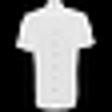

test:765 · 정답 Shirt · 학습 후 T - shirt / top


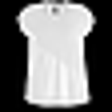

test:4231 · 정답 Shirt · 학습 후 T - shirt / top


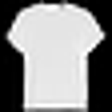

In [21]:
n = len(comparison)
before_score = before_metrics["accuracy"]
after_score = after_metrics["accuracy"]
improved = int((~comparison["before_correct"] & comparison["after_correct"]).sum())
regressed = int((comparison["before_correct"] & ~comparison["after_correct"]).sum())
failed = comparison.loc[~comparison["after_correct"]]
first_val, last_val = validation_log.iloc[0], validation_log.iloc[-1]

display(Markdown(
    f"**Test {n}개에서 Accuracy {before_score:.2%} → {after_score:.2%} "
    f"({(after_score - before_score) * 100:+.2f}%p)**\n\n"
    f"오답 → 정답은 {improved}개, 정답 → 오답은 {regressed}개였고, "
    f"학습 후 오분류는 총 {len(failed)}개였다. "
    f"Validation Accuracy는 첫 epoch {first_val.eval_accuracy:.2%}에서 "
    f"마지막 epoch {last_val.eval_accuracy:.2%}로 변했고, "
    f"같은 구간의 Loss는 {first_val.eval_loss:.3f} → {last_val.eval_loss:.3f}였다."
))
if not failed.empty:
    confusions = failed.groupby(["target", "after"]).size().sort_values(ascending=False)
    actual, predicted = confusions.index[0]
    print(f"가장 빈번한 오분류 · {id2label[actual]} → {id2label[predicted]} ({confusions.iloc[0]}개)")
    examples = failed.loc[(failed["target"] == actual) & (failed["after"] == predicted)]
    for row in pd.concat([examples, failed]).drop_duplicates("source_id").head(3).itertuples():
        print(f"{row.source_id} · 정답 {id2label[row.target]} · 학습 후 {id2label[row.after]}")
        display(raw["test"][row.sample_id]["image"].resize((112, 112)))